# 3. Multi-view Mammography Classification

This notebook investigates whether combining CC and MLO mammographic views improves breast-level abnormality classification.

A two-branch ResNet50 architecture is implemented using feature concatenation. The same data partitions, preprocessing strategy, and evaluation procedure are retained from the single-view experiments.

## 3.1 Data Preparation

In [1]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from torchvision.transforms import functional as TF

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

In [2]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

### 1. Define paths

In [3]:
PROJECT_DIR = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

DATA_DIR = PROJECT_DIR / "data"
SPLIT_DIR = DATA_DIR / "splits"
MODEL_DIR = PROJECT_DIR / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Project:", PROJECT_DIR)

Device: cuda
Project: c:\Users\Admin\Desktop\Projects\5_sem\DeepLearning\lab4


### 2. Load prepared data

In [4]:
train_df = pd.read_csv(SPLIT_DIR / "train_pairs.csv")
val_df = pd.read_csv(SPLIT_DIR / "val_pairs.csv")
test_df = pd.read_csv(SPLIT_DIR / "test_pairs.csv")

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

train_df[
    ["study_id", "laterality", "CC_path", "MLO_path", "target"]
].head()

Train: 1352
Validation: 1150
Test: 1907


,study_id,laterality,CC_path,MLO_path,target
0,27da2a953a5b5d4f4b87b65dbc2ebe91,R,D:\images_png\27da2a953a5b5d4f4b87b65dbc2ebe91...,D:\images_png\27da2a953a5b5d4f4b87b65dbc2ebe91...,1
1,b927d189be4fcf2cadfbb6d30fbd6bca,R,D:\images_png\b927d189be4fcf2cadfbb6d30fbd6bca...,D:\images_png\b927d189be4fcf2cadfbb6d30fbd6bca...,0
2,bdc1f8421da54f78324143bc594507a3,L,D:\images_png\bdc1f8421da54f78324143bc594507a3...,D:\images_png\bdc1f8421da54f78324143bc594507a3...,0
3,357014e8a48f0f7051717aa965f4deb5,R,D:\images_png\357014e8a48f0f7051717aa965f4deb5...,D:\images_png\357014e8a48f0f7051717aa965f4deb5...,0
4,53e742eb8e91caa870b5dc1fafeec048,L,D:\images_png\53e742eb8e91caa870b5dc1fafeec048...,D:\images_png\53e742eb8e91caa870b5dc1fafeec048...,0


### 3. Pairs and Data Leakage check

In [5]:
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    assert df[["CC_path", "MLO_path"]].notna().all().all()

    print(
        f"{name}: {len(df)} breast pairs, "
        f"{df['target'].sum()} positive"
    )

train_ids = set(train_df["study_id"])
val_ids = set(val_df["study_id"])
test_ids = set(test_df["study_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("No study-level leakage detected.")

Train: 1352 breast pairs, 338 positive
Validation: 1150 breast pairs, 57 positive
Test: 1907 breast pairs, 99 positive
No study-level leakage detected.


## 3.2 Multi-view Dataset

CC and MLO images of the same breast are loaded as paired inputs. The same aspect-ratio-preserving resize and ImageNet normalization used in the single-view baseline are applied to both views.

In [6]:
class ResizeWithPadding:
    def __init__(self, size):
        self.size = size

    def __call__(self, image):
        image = image.copy()

        image.thumbnail(
            (self.size, self.size),
            Image.Resampling.BILINEAR
        )

        width, height = image.size

        padding = (
            (self.size - width) // 2,
            (self.size - height) // 2,
            self.size - width - (self.size - width) // 2,
            self.size - height - (self.size - height) // 2
        )

        return TF.pad(image, padding, fill=0)


IMAGE_SIZE = 224

image_transform = transforms.Compose([
    ResizeWithPadding(IMAGE_SIZE),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [7]:
class MultiViewMammographyDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        with Image.open(row["CC_path"]) as img:
            cc_image = img.convert("RGB")

        with Image.open(row["MLO_path"]) as img:
            mlo_image = img.convert("RGB")

        if self.transform:
            cc_image = self.transform(cc_image)
            mlo_image = self.transform(mlo_image)

        label = torch.tensor(
            row["target"],
            dtype=torch.float32
        )

        return cc_image, mlo_image, label

In [8]:
train_dataset = MultiViewMammographyDataset(
    train_df,
    transform=image_transform
)

val_dataset = MultiViewMammographyDataset(
    val_df,
    transform=image_transform
)

test_dataset = MultiViewMammographyDataset(
    test_df,
    transform=image_transform
)

cc, mlo, label = train_dataset[0]

print("CC shape:", cc.shape)
print("MLO shape:", mlo.shape)
print("Target:", label)

CC shape: torch.Size([3, 224, 224])
MLO shape: torch.Size([3, 224, 224])
Target: tensor(1.)


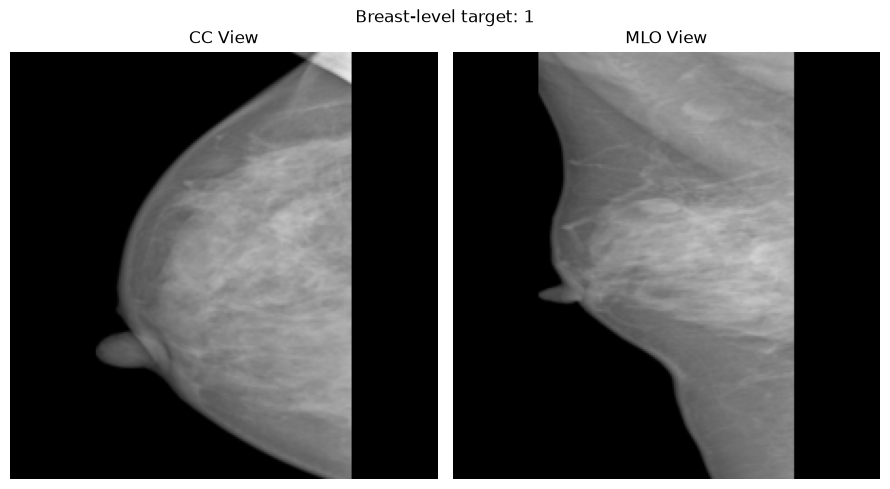

In [9]:
def denormalize(image):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    return (image.cpu() * std + mean).clamp(0, 1)


cc, mlo, label = train_dataset[0]

fig, axes = plt.subplots(1, 2, figsize=(9, 5))

axes[0].imshow(denormalize(cc).permute(1, 2, 0))
axes[0].set_title("CC View")
axes[0].axis("off")

axes[1].imshow(denormalize(mlo).permute(1, 2, 0))
axes[1].set_title("MLO View")
axes[1].axis("off")

plt.suptitle(f"Breast-level target: {int(label.item())}")
plt.tight_layout()
plt.show()

In [10]:
BATCH_SIZE = 2
EPOCHS = 10
LEARNING_RATE = 1e-4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

cc_batch, mlo_batch, labels = next(iter(train_loader))

print("CC batch:", cc_batch.shape)
print("MLO batch:", mlo_batch.shape)
print("Labels:", labels.shape)

CC batch: torch.Size([2, 3, 224, 224])
MLO batch: torch.Size([2, 3, 224, 224])
Labels: torch.Size([2])


## 3.3 Multi-view Architecture

Two ImageNet-pretrained ResNet50 encoders independently extract features from CC and MLO views. The resulting feature vectors are concatenated and passed to a fully connected classifier for breast-level prediction.

In [11]:
class MultiViewResNet50(nn.Module):

    def __init__(self, pretrained=True):
        super().__init__()

        weights = (
            models.ResNet50_Weights.DEFAULT
            if pretrained else None
        )

        self.cc_encoder = models.resnet50(weights=weights)
        self.mlo_encoder = models.resnet50(weights=weights)

        feature_dim = self.cc_encoder.fc.in_features

        # Remove original ImageNet classification layers
        self.cc_encoder.fc = nn.Identity()
        self.mlo_encoder.fc = nn.Identity()

        # Concatenate CC and MLO features
        self.classifier = nn.Sequential(
            nn.Linear(feature_dim * 2, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 1)
        )

    def forward(self, cc, mlo):

        cc_features = self.cc_encoder(cc)
        mlo_features = self.mlo_encoder(mlo)

        combined = torch.cat(
            [cc_features, mlo_features],
            dim=1
        )

        logits = self.classifier(combined)

        return logits

In [12]:
model = MultiViewResNet50(pretrained=True).to(device)

for encoder in [model.cc_encoder, model.mlo_encoder]:
    for parameter in encoder.parameters():
        parameter.requires_grad = False

model.eval()

cc_batch, mlo_batch, labels = next(iter(train_loader))

with torch.no_grad():
    logits = model(
        cc_batch.to(device),
        mlo_batch.to(device)
    )

print("Output shape:", logits.shape)
print("Probabilities:", torch.sigmoid(logits).cpu().flatten())

Output shape: torch.Size([2, 1])
Probabilities: tensor([0.4991, 0.5187])


## 3.4 Multi-view Training and Validation

The initial multi-view model is trained using frozen ImageNet-pretrained ResNet50 encoders, while the fusion classifier remains trainable. This configuration reduces computational requirements and establishes a preliminary concatenation-based baseline.

In [13]:
def train_one_epoch_multiview(
    model,
    loader,
    criterion,
    optimizer,
    device
):
    model.train()

    # Keep frozen encoders in evaluation mode
    model.cc_encoder.eval()
    model.mlo_encoder.eval()

    running_loss = 0.0

    for cc_images, mlo_images, labels in loader:
        cc_images = cc_images.to(device)
        mlo_images = mlo_images.to(device)
        labels = labels.to(device).unsqueeze(1)

        optimizer.zero_grad()

        logits = model(cc_images, mlo_images)

        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * cc_images.size(0)

    return running_loss / len(loader.dataset)

In [14]:
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.classifier.parameters(),
    lr=LEARNING_RATE
)

print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

Trainable parameters: 1049089


In [15]:
def evaluate_multiview(
    model,
    loader,
    criterion,
    device
):
    model.eval()

    running_loss = 0.0
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for cc_images, mlo_images, labels in loader:
            cc_images = cc_images.to(device)
            mlo_images = mlo_images.to(device)
            labels = labels.to(device).unsqueeze(1)

            logits = model(cc_images, mlo_images)

            loss = criterion(logits, labels)
            probs = torch.sigmoid(logits)

            running_loss += loss.item() * cc_images.size(0)

            all_labels.extend(
                labels.cpu().numpy().ravel()
            )
            all_probs.extend(
                probs.cpu().numpy().ravel()
            )

    avg_loss = running_loss / len(loader.dataset)

    return (
        avg_loss,
        np.array(all_labels),
        np.array(all_probs)
    )

In [16]:
train_losses = []
val_losses = []

best_val_loss = float("inf")
best_epoch = 0
best_model_state = None

for epoch in range(EPOCHS):

    train_loss = train_one_epoch_multiview(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_labels, val_probs = evaluate_multiview(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1

        best_model_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch 01/10 | Train Loss: 0.5507 | Val Loss: 0.3821
Epoch 02/10 | Train Loss: 0.5175 | Val Loss: 0.3163
Epoch 03/10 | Train Loss: 0.5009 | Val Loss: 0.3502
Epoch 04/10 | Train Loss: 0.4724 | Val Loss: 0.3844
Epoch 05/10 | Train Loss: 0.4611 | Val Loss: 0.3988
Epoch 06/10 | Train Loss: 0.4423 | Val Loss: 0.3157
Epoch 07/10 | Train Loss: 0.4200 | Val Loss: 0.2383
Epoch 08/10 | Train Loss: 0.4003 | Val Loss: 0.2232
Epoch 09/10 | Train Loss: 0.3865 | Val Loss: 0.3467
Epoch 10/10 | Train Loss: 0.3620 | Val Loss: 0.3164


In [17]:
model.load_state_dict(best_model_state)

print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))

Best epoch: 8
Best validation loss: 0.2232


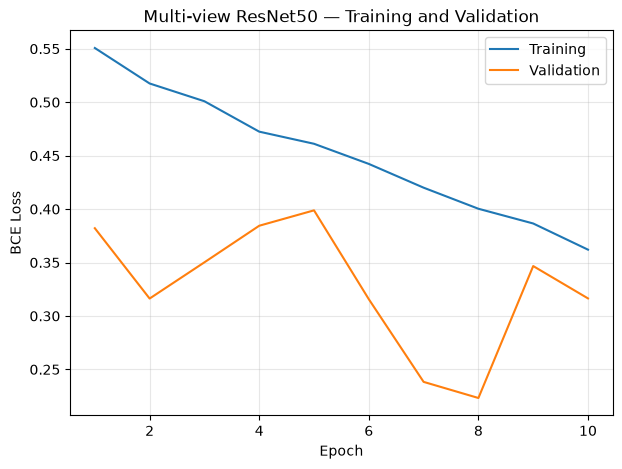

In [18]:
plt.figure(figsize=(7, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_losses,
    label="Training"
)

plt.plot(
    range(1, EPOCHS + 1),
    val_losses,
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Multi-view ResNet50 — Training and Validation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Training loss decreases throughout the experiment, while validation loss fluctuates and reaches its minimum at epoch 8. The corresponding model checkpoint is selected for evaluation.

## 3.5 Preliminary Validation Results

The concatenation-based multi-view model is evaluated using AUROC, AUPRC, sensitivity, specificity, precision, and F1-score. These preliminary results are used to assess the frozen-encoder baseline before further fine-tuning.

In [19]:
val_loss, val_labels, val_probs = evaluate_multiview(
    model,
    val_loader,
    criterion,
    device
)

val_preds = (val_probs >= 0.5).astype(int)

In [20]:
tn, fp, fn, tp = confusion_matrix(
    val_labels,
    val_preds,
    labels=[0, 1]
).ravel()

metrics = {
    "AUROC": roc_auc_score(val_labels, val_probs),
    "AUPRC": average_precision_score(val_labels, val_probs),
    "Sensitivity": recall_score(
        val_labels, val_preds, zero_division=0
    ),
    "Specificity": tn / (tn + fp),
    "Precision": precision_score(
        val_labels, val_preds, zero_division=0
    ),
    "F1": f1_score(
        val_labels, val_preds, zero_division=0
    )
}

pd.Series(metrics).round(4)

AUROC          0.7373
AUPRC          0.1532
Sensitivity    0.1228
Specificity    0.9899
Precision      0.3889
F1             0.1867
dtype: float64

The frozen-encoder multi-view model achieved an AUROC of 0.7373, slightly exceeding the CC-only baseline. However, its lower AUPRC and sensitivity indicate limited detection of suspicious cases. Further encoder fine-tuning is required before drawing conclusions about the contribution of multi-view fusion.

In [21]:
torch.save(
    {
        "model_name": "multiview_resnet50",
        "fusion": "concatenation",
        "encoder_training": "frozen",
        "state_dict": model.state_dict(),
        "best_epoch": best_epoch,
        "image_size": IMAGE_SIZE,
        "seed": SEED
    },
    MODEL_DIR / "multiview_concat_frozen_best.pth"
)

print("Checkpoint saved.")

Checkpoint saved.


## 3.6 Partial Fine-tuning

The final residual block of each ResNet50 encoder is unfrozen to adapt high-level features to mammography, while earlier layers remain frozen. A lower learning rate is applied to the encoders than to the fusion classifier.

In [22]:
FT_CHECKPOINT = MODEL_DIR / "multiview_concat_frozen_best.pth"

checkpoint = torch.load(
    FT_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

ft_model = MultiViewResNet50(pretrained=False)

ft_model.load_state_dict(checkpoint["state_dict"])
ft_model = ft_model.to(device)

print("Loaded frozen baseline from epoch:", checkpoint["best_epoch"])

Loaded frozen baseline from epoch: 8


In [23]:
# Freeze all parameters first
for parameter in ft_model.parameters():
    parameter.requires_grad = False

# Unfreeze layer4 in both encoders
for encoder in [ft_model.cc_encoder, ft_model.mlo_encoder]:
    for parameter in encoder.layer4.parameters():
        parameter.requires_grad = True

# Keep fusion classifier trainable
for parameter in ft_model.classifier.parameters():
    parameter.requires_grad = True

trainable_params = sum(
    p.numel() for p in ft_model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", f"{trainable_params:,}")

Trainable parameters: 30,978,561


In [24]:
FT_EPOCHS = 5

ft_criterion = nn.BCEWithLogitsLoss()

ft_optimizer = torch.optim.Adam([
    {
        "params": ft_model.cc_encoder.layer4.parameters(),
        "lr": 1e-5
    },
    {
        "params": ft_model.mlo_encoder.layer4.parameters(),
        "lr": 1e-5
    },
    {
        "params": ft_model.classifier.parameters(),
        "lr": 1e-4
    }
])

USE_AMP = device.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

In [25]:
def train_one_epoch_finetune(
    model,
    loader,
    criterion,
    optimizer,
    scaler,
    device
):
    model.train()

    # Keep BatchNorm statistics fixed in both encoders
    model.cc_encoder.eval()
    model.mlo_encoder.eval()
    model.classifier.train()

    running_loss = 0.0

    for cc_images, mlo_images, labels in loader:
        cc_images = cc_images.to(device)
        mlo_images = mlo_images.to(device)
        labels = labels.to(device).unsqueeze(1)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            enabled=USE_AMP
        ):
            logits = model(cc_images, mlo_images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * cc_images.size(0)

    return running_loss / len(loader.dataset)

In [26]:
ft_train_losses = []
ft_val_losses = []

ft_best_val_loss = float("inf")
ft_best_epoch = 0
ft_best_state = None

for epoch in range(FT_EPOCHS):

    train_loss = train_one_epoch_finetune(
        ft_model,
        train_loader,
        ft_criterion,
        ft_optimizer,
        scaler,
        device
    )

    val_loss, _, _ = evaluate_multiview(
        ft_model,
        val_loader,
        ft_criterion,
        device
    )

    ft_train_losses.append(train_loss)
    ft_val_losses.append(val_loss)

    if val_loss < ft_best_val_loss:
        ft_best_val_loss = val_loss
        ft_best_epoch = epoch + 1

        ft_best_state = {
            key: value.detach().cpu().clone()
            for key, value in ft_model.state_dict().items()
        }

    print(
        f"Epoch {epoch + 1:02d}/{FT_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch 01/5 | Train Loss: 0.4304 | Val Loss: 0.2383
Epoch 02/5 | Train Loss: 0.2610 | Val Loss: 0.3714
Epoch 03/5 | Train Loss: 0.1125 | Val Loss: 0.2466
Epoch 04/5 | Train Loss: 0.0593 | Val Loss: 0.2449
Epoch 05/5 | Train Loss: 0.0110 | Val Loss: 0.3223


In [27]:
ft_model.load_state_dict(ft_best_state)

print("Best epoch:", ft_best_epoch)
print("Best validation loss:", round(ft_best_val_loss, 4))

Best epoch: 1
Best validation loss: 0.2383


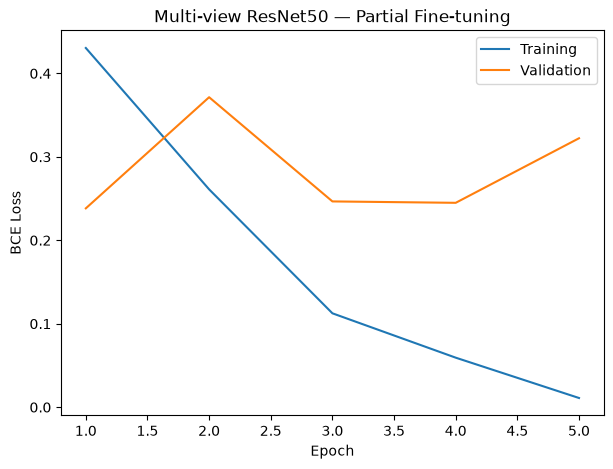

In [32]:
plt.figure(figsize=(7, 5))

plt.plot(
    range(1, FT_EPOCHS + 1),
    ft_train_losses,
    label="Training"
)

plt.plot(
    range(1, FT_EPOCHS + 1),
    ft_val_losses,
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Multi-view ResNet50 — Partial Fine-tuning")
plt.legend()
plt.show()

Training loss decreases sharply, while validation loss reaches its minimum at the first epoch and subsequently fluctuates, indicating overfitting during partial fine-tuning.

In [29]:
ft_val_loss, ft_labels, ft_probs = evaluate_multiview(
    ft_model,
    val_loader,
    ft_criterion,
    device
)

ft_preds = (ft_probs >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(
    ft_labels,
    ft_preds,
    labels=[0, 1]
).ravel()

ft_metrics = {
    "AUROC": roc_auc_score(ft_labels, ft_probs),
    "AUPRC": average_precision_score(ft_labels, ft_probs),
    "Sensitivity": recall_score(
        ft_labels, ft_preds, zero_division=0
    ),
    "Specificity": tn / (tn + fp),
    "Precision": precision_score(
        ft_labels, ft_preds, zero_division=0
    ),
    "F1": f1_score(
        ft_labels, ft_preds, zero_division=0
    )
}

pd.Series(ft_metrics).round(4)

AUROC          0.7188
AUPRC          0.1716
Sensitivity    0.1754
Specificity    0.9780
Precision      0.2941
F1             0.2198
dtype: float64

In [30]:
comparison_df = pd.DataFrame([
    {
        "Configuration": "Frozen encoders",
        **metrics
    },
    {
        "Configuration": "Partial fine-tuning",
        **ft_metrics
    }
])

comparison_df.round(4)

,Configuration,AUROC,AUPRC,Sensitivity,Specificity,Precision,F1
0,Frozen encoders,0.7373,0.1532,0.1228,0.9899,0.3889,0.1867
1,Partial fine-tuning,0.7188,0.1716,0.1754,0.9780,0.2941,0.2198


Partial fine-tuning improved AUPRC, sensitivity, and F1-score, but reduced AUROC, specificity, and precision. The mixed results suggest limited generalization benefits from unfreezing the final encoder blocks under the current training configuration.

In [ ]:
torch.save(
    {
        "initial_training": "frozen_encoders_10_epochs",
        "fine_tuning": "layer4_5_epochs",
        "model_name": "multiview_resnet50",
        "fusion": "concatenation",
        "encoder_training": "partial_layer4",
        "state_dict": ft_model.state_dict(),
        "best_epoch": ft_best_epoch,
        "image_size": IMAGE_SIZE,
        "seed": SEED,
        "encoder_lr": 1e-5,
        "classifier_lr": 1e-4
    },
    MODEL_DIR / "multiview_concat_partial_best.pth"
)

comparison_df.to_csv(
    PROJECT_DIR / "results" / "experiments" / "multiview_finetuning_results.csv",
    index=False
)

## 3.7 Attention-based Fusion

An attention-based fusion mechanism is introduced to learn the relative contribution of CC and MLO features for each breast. Both ResNet50 encoders remain frozen, allowing the fusion strategy to be investigated without additional encoder fine-tuning.

In [35]:
class AttentionFusionHead(nn.Module):

    def __init__(self, feature_dim=2048):
        super().__init__()

        self.attention = nn.Sequential(
            nn.Linear(feature_dim, 128),
            nn.Tanh(),
            nn.Linear(128, 1)
        )

        self.classifier = nn.Sequential(
            nn.Linear(feature_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 1)
        )

    def forward(self, cc_features, mlo_features):

        features = torch.stack(
            [cc_features, mlo_features],
            dim=1
        )

        scores = self.attention(features)

        weights = torch.softmax(scores, dim=1)

        fused = (features * weights).sum(dim=1)

        logits = self.classifier(fused)

        return logits, weights.squeeze(-1)

In [37]:
class ConcatenationFusionHead(nn.Module):

    def __init__(self, feature_dim=2048):
        super().__init__()

        self.classifier = nn.Sequential(
            nn.Linear(feature_dim * 2, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 1)
        )

    def forward(self, cc_features, mlo_features):

        fused = torch.cat(
            [cc_features, mlo_features],
            dim=1
        )

        return self.classifier(fused)

Frozen CNN features are extracted once for each breast pair and cached in memory. Both fusion models are subsequently trained using the same feature representations, ensuring a consistent input configuration and reducing computational cost.

In [38]:
frozen_checkpoint = torch.load(
    MODEL_DIR / "multiview_concat_frozen_best.pth",
    map_location="cpu",
    weights_only=True
)

feature_model = MultiViewResNet50(pretrained=False)
feature_model.load_state_dict(frozen_checkpoint["state_dict"])
feature_model = feature_model.to(device)

feature_model.eval()

for parameter in feature_model.parameters():
    parameter.requires_grad = False

print("Frozen encoders loaded.")

Frozen encoders loaded.


In [39]:
def extract_multiview_features(model, loader, device):

    model.eval()

    cc_features_list = []
    mlo_features_list = []
    labels_list = []

    with torch.inference_mode():
        for cc_images, mlo_images, labels in loader:

            cc_images = cc_images.to(device)
            mlo_images = mlo_images.to(device)

            cc_features = model.cc_encoder(cc_images)
            mlo_features = model.mlo_encoder(mlo_images)

            cc_features_list.append(cc_features.cpu())
            mlo_features_list.append(mlo_features.cpu())
            labels_list.append(labels.cpu())

    return (
        torch.cat(cc_features_list, dim=0),
        torch.cat(mlo_features_list, dim=0),
        torch.cat(labels_list, dim=0)
    )

In [40]:
feature_train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

feature_val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

In [41]:
train_cc, train_mlo, train_labels = extract_multiview_features(
    feature_model, feature_train_loader, device
)

val_cc, val_mlo, val_labels_cached = extract_multiview_features(
    feature_model, feature_val_loader, device
)

print("Train CC:", train_cc.shape)
print("Train MLO:", train_mlo.shape)
print("Validation CC:", val_cc.shape)
print("Validation MLO:", val_mlo.shape)

Train CC: torch.Size([1352, 2048])
Train MLO: torch.Size([1352, 2048])
Validation CC: torch.Size([1150, 2048])
Validation MLO: torch.Size([1150, 2048])


In [42]:
del feature_model

if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [43]:
from torch.utils.data import TensorDataset

train_feature_dataset = TensorDataset(
    train_cc, train_mlo, train_labels
)

val_feature_dataset = TensorDataset(
    val_cc, val_mlo, val_labels_cached
)

feature_batch_size = 32

train_feature_loader = DataLoader(
    train_feature_dataset,
    batch_size=feature_batch_size,
    shuffle=True
)

val_feature_loader = DataLoader(
    val_feature_dataset,
    batch_size=feature_batch_size,
    shuffle=False
)

In [44]:
def get_fusion_logits(model, cc, mlo):

    output = model(cc, mlo)

    if isinstance(output, tuple):
        return output[0]

    return output

In [45]:
def train_fusion_epoch(model, loader, criterion, optimizer, device):

    model.train()
    total_loss = 0.0

    for cc, mlo, labels in loader:

        cc = cc.to(device)
        mlo = mlo.to(device)
        labels = labels.to(device).unsqueeze(1)

        optimizer.zero_grad()

        logits = get_fusion_logits(model, cc, mlo)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(labels)

    return total_loss / len(loader.dataset)

In [46]:
def evaluate_fusion(model, loader, criterion, device):

    model.eval()

    total_loss = 0.0
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for cc, mlo, labels in loader:

            cc = cc.to(device)
            mlo = mlo.to(device)
            labels = labels.to(device).unsqueeze(1)

            logits = get_fusion_logits(model, cc, mlo)
            loss = criterion(logits, labels)

            probs = torch.sigmoid(logits)

            total_loss += loss.item() * len(labels)

            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy().ravel())

    return (
        total_loss / len(loader.dataset),
        np.array(all_labels),
        np.array(all_probs)
    )

In [47]:
def train_fusion_model(model, train_loader, val_loader, device):

    model = model.to(device)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-4
    )

    train_losses = []
    val_losses = []

    best_loss = float("inf")
    best_epoch = 0
    best_state = None

    for epoch in range(10):

        train_loss = train_fusion_epoch(
            model, train_loader, criterion, optimizer, device
        )

        val_loss, _, _ = evaluate_fusion(
            model, val_loader, criterion, device
        )

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch + 1
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(
            f"Epoch {epoch+1:02d}/10 | "
            f"Train: {train_loss:.4f} | "
            f"Val: {val_loss:.4f}"
        )

    model.load_state_dict(best_state)

    return model, train_losses, val_losses, best_epoch

In [48]:
set_seed(42)

concat_head = ConcatenationFusionHead()

concat_head, concat_train_losses, concat_val_losses, concat_epoch = (
    train_fusion_model(
        concat_head,
        train_feature_loader,
        val_feature_loader,
        device
    )
)

Epoch 01/10 | Train: 0.5655 | Val: 0.3176
Epoch 02/10 | Train: 0.5394 | Val: 0.3157
Epoch 03/10 | Train: 0.5223 | Val: 0.3283
Epoch 04/10 | Train: 0.5088 | Val: 0.3004
Epoch 05/10 | Train: 0.4965 | Val: 0.3203
Epoch 06/10 | Train: 0.4955 | Val: 0.3343
Epoch 07/10 | Train: 0.4762 | Val: 0.3129
Epoch 08/10 | Train: 0.4727 | Val: 0.3136
Epoch 09/10 | Train: 0.4604 | Val: 0.3641
Epoch 10/10 | Train: 0.4503 | Val: 0.2902


In [49]:
set_seed(42)

attention_head = AttentionFusionHead()

attention_head, attention_train_losses, attention_val_losses, attention_epoch = (
    train_fusion_model(
        attention_head,
        train_feature_loader,
        val_feature_loader,
        device
    )
)

Epoch 01/10 | Train: 0.5812 | Val: 0.3329
Epoch 02/10 | Train: 0.5477 | Val: 0.3166
Epoch 03/10 | Train: 0.5371 | Val: 0.3476
Epoch 04/10 | Train: 0.5258 | Val: 0.3158
Epoch 05/10 | Train: 0.5147 | Val: 0.3129
Epoch 06/10 | Train: 0.5043 | Val: 0.3667
Epoch 07/10 | Train: 0.4926 | Val: 0.2999
Epoch 08/10 | Train: 0.4728 | Val: 0.3181
Epoch 09/10 | Train: 0.4584 | Val: 0.2760
Epoch 10/10 | Train: 0.4439 | Val: 0.3099


In [50]:
def fusion_metrics(model, loader):

    _, labels, probs = evaluate_fusion(
        model,
        loader,
        nn.BCEWithLogitsLoss(),
        device
    )

    preds = (probs >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels, preds, labels=[0, 1]
    ).ravel()

    return {
        "AUROC": roc_auc_score(labels, probs),
        "AUPRC": average_precision_score(labels, probs),
        "Sensitivity": recall_score(labels, preds, zero_division=0),
        "Specificity": tn / (tn + fp),
        "Precision": precision_score(labels, preds, zero_division=0),
        "F1": f1_score(labels, preds, zero_division=0)
    }


concat_metrics = fusion_metrics(
    concat_head, val_feature_loader
)

attention_metrics = fusion_metrics(
    attention_head, val_feature_loader
)

fusion_comparison = pd.DataFrame([
    {"Fusion": "Concatenation", **concat_metrics},
    {"Fusion": "Attention", **attention_metrics}
])

fusion_comparison.round(4)

,Fusion,AUROC,AUPRC,Sensitivity,Specificity,Precision,F1
0,Concatenation,0.7217,0.1527,0.1228,0.9817,0.2593,0.1667
1,Attention,0.6786,0.1226,0.1228,0.9808,0.2500,0.1647


The controlled fusion comparison showed that concatenation outperformed attention-based fusion in AUROC, AUPRC, and F1-score. Although the attention model achieved a lower minimum validation loss, it did not improve discrimination between suspicious and non-suspicious cases. These results are preliminary and require repeated experiments to assess their stability.

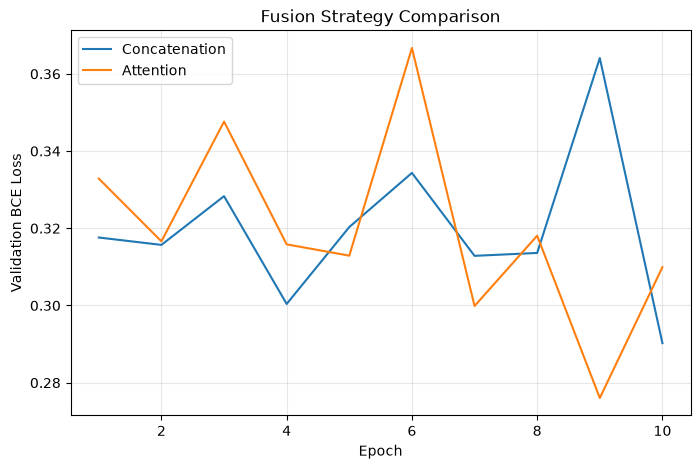

In [54]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(concat_val_losses) + 1),
    concat_val_losses,
    label="Concatenation"
)

plt.plot(
    range(1, len(attention_val_losses) + 1),
    attention_val_losses,
    label="Attention"
)

plt.xlabel("Epoch")
plt.ylabel("Validation BCE Loss")
plt.title("Fusion Strategy Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [52]:
attention_head.eval()

cc_batch, mlo_batch, labels = next(iter(val_feature_loader))

with torch.no_grad():
    logits, weights = attention_head(
        cc_batch.to(device),
        mlo_batch.to(device)
    )

print("Attention weights [CC, MLO]:")
print(weights[:10].cpu().numpy().round(3))

Attention weights [CC, MLO]:
[[0.265 0.735]
 [0.275 0.725]
 [0.48  0.52 ]
 [0.233 0.767]
 [0.482 0.518]
 [0.482 0.518]
 [0.211 0.789]
 [0.152 0.848]
 [0.563 0.437]
 [0.468 0.532]]


The learned attention weights vary across breast pairs, indicating that the model assigns different relative importance to CC and MLO features. However, these weights should not be interpreted as direct evidence of clinical relevance.

In [ ]:
torch.save(
    {
        "fusion": "concatenation",
        "state_dict": concat_head.state_dict(),
        "best_epoch": concat_epoch,
        "seed": SEED,
        "feature_dim": 2048,
        "encoder_checkpoint": "multiview_concat_frozen_best.pth"
    },
    MODEL_DIR / "concat_head_controlled.pth"
)

torch.save(
    {
        "fusion": "attention",
        "state_dict": attention_head.state_dict(),
        "best_epoch": attention_epoch,
        "seed": SEED,
        "feature_dim": 2048,
        "encoder_checkpoint": "multiview_concat_frozen_best.pth"
    },
    MODEL_DIR / "attention_head_controlled.pth"
)

fusion_comparison.to_csv(
    PROJECT_DIR / "results" / "experiments" / "fusion_comparison.csv",
    index=False
)

print("Fusion experiments saved.")

Fusion experiments saved.


## 3.8 Final Multi-view Comparison

This section summarizes the validation performance of single-view and multi-view ResNet50 configurations. The comparison includes CC-only, MLO-only, concatenation-based fusion, partial encoder fine-tuning, and attention-based fusion.

All configurations are evaluated on the same validation partition. However, differences in encoder training strategies and fusion architectures must be considered when interpreting the results.

In [ ]:
single_view_results = pd.read_csv(
    PROJECT_DIR / "results" / "experiments" / "single_view_comparison.csv"
)

single_view_results = single_view_results.set_index("View")

single_view_results

,AUROC,AUPRC,Sensitivity,Specificity,F1
View,,,,,
CC,0.731577,0.226174,0.263158,0.968893,0.283019
MLO,0.672525,0.134381,0.157895,0.959744,0.163636


In [80]:
final_comparison = pd.DataFrame([
    {
        "Configuration": "CC-only",
        **single_view_results.loc["CC"].to_dict()
    },
    {
        "Configuration": "MLO-only",
        **single_view_results.iloc[1].drop("View").to_dict()
    },
    {
        "Configuration": "CC+MLO Frozen",
        **metrics
    },
    {
        "Configuration": "CC+MLO Partial FT",
        **ft_metrics
    },
    {
        "Configuration": "CC+MLO Concatenation",
        **concat_metrics
    },
    {
        "Configuration": "CC+MLO Attention",
        **attention_metrics
    }
])

final_comparison = final_comparison.set_index("Configuration")

final_comparison.round(4)

,AUROC,AUPRC,Sensitivity,Specificity,F1,Precision
Configuration,,,,,,
CC-only,0.7316,0.2262,0.2632,0.9689,0.2830,NaN
MLO-only,0.6725,0.1344,0.1579,0.9597,0.1636,NaN
CC+MLO Frozen,0.7373,0.1532,0.1228,0.9899,0.1867,0.3889
CC+MLO Partial FT,0.7188,0.1716,0.1754,0.9780,0.2198,0.2941
CC+MLO Concatenation,0.7217,0.1527,0.1228,0.9817,0.1667,0.2593
CC+MLO Attention,0.6786,0.1226,0.1228,0.9808,0.1647,0.2500


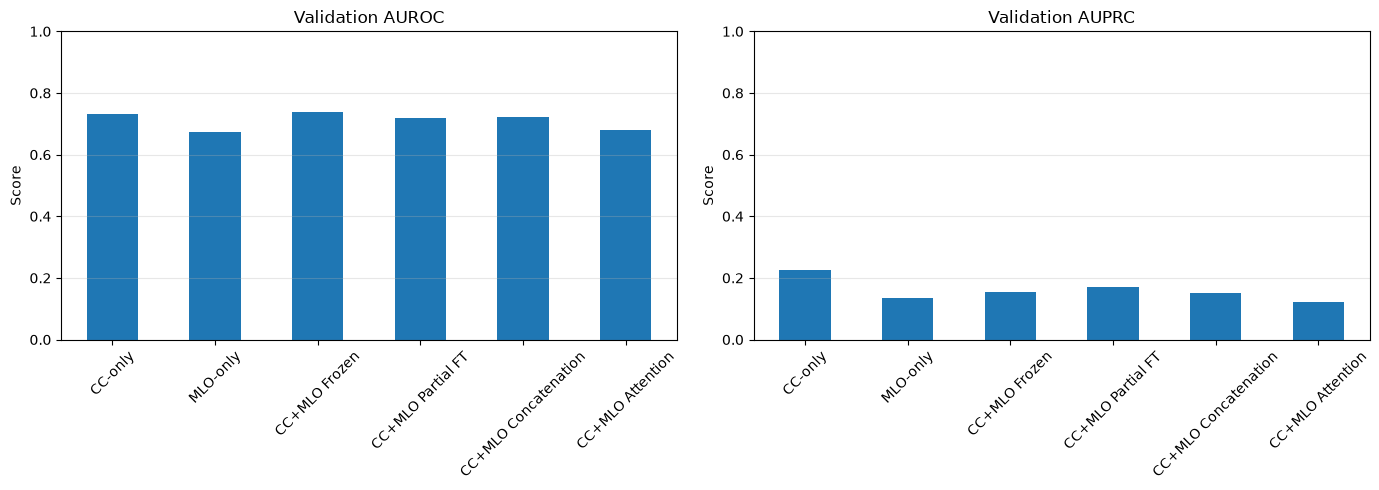

In [84]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

final_comparison["AUROC"].plot(
    kind="bar",
    ax=axes[0],
    title="Validation AUROC"
)

final_comparison["AUPRC"].plot(
    kind="bar",
    ax=axes[1],
    title="Validation AUPRC"
)

for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [85]:
for metric in ["AUROC", "AUPRC", "Sensitivity", "F1"]:
    best_model = final_comparison[metric].idxmax()
    best_score = final_comparison[metric].max()

    print(f"{metric}: {best_model} ({best_score:.4f})")

AUROC: CC+MLO Frozen (0.7373)
AUPRC: CC-only (0.2262)
Sensitivity: CC-only (0.2632)
F1: CC-only (0.2830)


The CC-only ResNet50 achieved the highest validation AUPRC and F1-score, whereas frozen concatenation achieved the highest AUROC. Partial fine-tuning improved sensitivity relative to the frozen multi-view baseline but showed signs of overfitting.

In the controlled fusion experiment, concatenation outperformed attention-based fusion in AUROC, AUPRC, and F1-score. Overall, multi-view fusion did not demonstrate a consistent improvement over the CC-only baseline under the evaluated configurations.

In [ ]:
final_comparison.to_csv(
    PROJECT_DIR / "results" / "experiments" / "final_multiview_comparison.csv"
)

print("Final comparison saved.")

Final comparison saved.


## 3.9 Conclusion

Single-view and multi-view mammography classifiers were evaluated using consistent study-level data partitions. Multi-view concatenation, partial fine-tuning, and attention-based fusion were investigated.

The results suggest that combining CC and MLO views does not automatically improve classification performance. Limited positive training examples, class imbalance, and overfitting may contribute to the observed performance differences.

These findings remain preliminary because experiments were conducted using a single random seed and different encoder-training strategies. Further investigation of loss functions, image resolution, and repeated experiments is required before final test-set evaluation.